# Unidad 11. Módulos, paquetes y pruebas

**Duración orientativa:** 7 horas · **Versión:** 1.0 · **Unidad temática:** UT2

Cuando un programa crece, no conviene dejar todas las funciones en un único cuaderno o archivo. Los módulos y paquetes permiten organizar código reutilizable, mientras que las pruebas automatizadas comprueban que sus comportamientos se mantienen al modificarlo.

## Resultados de aprendizaje

Al finalizar podrás distinguir script, módulo y paquete; importar nombres de forma explícita; explicar la caché de importación; organizar funciones en un archivo Python; reconocer el propósito de la condición principal; escribir pruebas con assert y pytest; y ejecutar una suite de pruebas desde la terminal.

## 1. Módulos y paquetes

Un módulo es normalmente un archivo con extensión .py que contiene código Python: funciones, clases, constantes o instrucciones. Un mismo archivo puede ejecutarse como script o importarse desde otro código. Al importarlo, Python ejecuta su contenido una primera vez y crea un objeto módulo cuyos nombres se pueden usar mediante punto.

Un paquete organiza varios módulos en una carpeta. En proyectos actuales puede ser una carpeta con módulos que Python reconoce como espacio de paquete; incluir un archivo llamado __init__.py sigue siendo una práctica clara y compatible para declarar un paquete explícito. El objetivo es separar responsabilidades: por ejemplo, funciones de lecturas en un módulo y pruebas en otro lugar.

No uses nombres de módulos que coincidan con bibliotecas estándar, como json.py o pathlib.py. Python podría importar tu archivo local en vez de la biblioteca esperada.

In [ ]:
import math
from pathlib import Path

print(math.sqrt(81))
print(Path("datos").exists())


### Formas de importar

Import nombre_modulo conserva el espacio de nombres y hace visible el origen: math.sqrt. From modulo import nombre permite usar directamente el nombre importado. Una alias con as puede abreviar un nombre conocido, pero no debe ocultar su significado. Evita importar todo mediante asterisco: dificulta saber de dónde procede cada nombre y puede causar conflictos.

Python busca módulos siguiendo rutas configuradas. En un proyecto del curso, el archivo que importa y el módulo propio deben estar en una estructura coherente. No arregles un problema de importación añadiendo rutas personales al código: revisa primero el nombre, la carpeta y desde qué directorio se ejecuta.

## 2. Código reutilizable y condición principal

Un módulo debe contener principalmente definiciones reutilizables. Las demostraciones que solo deben ejecutarse al llamar un archivo como script se colocan bajo la condición si el nombre del módulo es principal. Cuando se importa, esa condición no se cumple; cuando se ejecuta directamente, sí. Esto evita que un import imprima resultados o realice tareas inesperadas.

Esquema recomendado:

~~~python
def clasificar(temperatura):
    ...

if __name__ == "__main__":
    print(clasificar(22.0))
~~~

### Importación y cuadernos

Python guarda los módulos importados en memoria para no ejecutarlos repetidamente. En JupyterLab, si modificas un archivo .py después de importarlo, el cuaderno puede seguir usando la versión anterior. La solución más clara durante el aprendizaje es reiniciar el kernel y ejecutar las celdas de nuevo. Existe importlib.reload, pero no debe utilizarse como sustituto de entender qué versión se ha cargado.

Guarda siempre el archivo .py antes de probarlo. Un error frecuente consiste en modificar una celda del cuaderno y esperar que cambie un módulo externo que no se ha guardado ni recargado.

## 3. Pruebas automatizadas

Una prueba define una expectativa verificable: dado un dato de entrada, una función debe producir un resultado. Assert es suficiente para comprobaciones sencillas. Pytest descubre normalmente archivos cuyo nombre empieza por test y funciones cuyo nombre empieza por test. Ejecuta cada prueba y presenta un resumen de éxitos o fallos.

Una prueba debe ser independiente, rápida y legible. Incluye casos normales, límites y datos especiales. Una prueba no demuestra que un programa sea perfecto, pero evita que un comportamiento ya comprobado se rompa sin aviso al modificar el código. Las pruebas describen también el contrato que espera el resto del proyecto.

In [ ]:
def es_adecuada(temperatura: float) -> bool:
    return 18 <= temperatura <= 27

assert es_adecuada(18) is True
assert es_adecuada(27) is True
assert es_adecuada(17.9) is False
print("Pruebas locales superadas.")


### Estructura de prueba con pytest

Para un módulo modulos/lecturas.py y una carpeta pruebas, una prueba puede escribirse así:

~~~python
from modulos.lecturas import clasificar_temperatura

def test_limite_inferior():
    assert clasificar_temperatura(18) == "adecuada"
~~~

Desde la raíz del curso, se ejecutaría python menos m pytest pruebas. El manual de instalación deja pytest disponible en el entorno del curso. Si no se encuentra el módulo, comprueba que trabajas desde la raíz y que la estructura de carpetas coincide con el import.

## 4. Diseño y depuración

Una función fácil de probar recibe datos y devuelve resultados, sin depender de entrada manual, archivos ocultos o variables globales. Separa la lectura de archivos, el cálculo y la presentación. Así puedes probar el cálculo con una lista pequeña sin necesitar un archivo real.

Cuando una prueba falla, lee primero el valor esperado y el obtenido. Reduce el problema a una llamada concreta, revisa el requisito y corrige la función o la prueba según cuál sea incoherente. No cambies una expectativa solo para que el resultado actual pase: una prueba debe expresar una regla del problema.

## Práctica guiada

1. Ejecuta el ejemplo de biblioteca estándar y explica qué nombre procede de cada módulo.
2. Añade una prueba para la temperatura 22 en es_adecuada.
3. Cambia temporalmente el operador menor o igual por menor y observa qué aserción falla. Restaura después la función.
4. En una celda Markdown, propone los nombres de un módulo y tres funciones para un proyecto de análisis de lecturas.
5. Explica por qué una impresión de demostración no debería ejecutarse al importar un módulo.

## Ejercicios

**Ejercicio 11.01 · Importaciones claras.** Importa datetime y Path de forma explícita. Muestra la fecha actual y construye una ruta relativa de informe. Explica qué problema evita la notación con punto tras importar un módulo completo.

**Ejercicio 11.02 · Diseño de módulo.** Diseña en Markdown el archivo modulos/confort.py con tres funciones: convertir_lectura, clasificar_temperatura y resumir_lecturas. Escribe para cada una parámetros, retorno y una responsabilidad. Indica qué demostración pondrías bajo la condición principal.

**Ejercicio 11.03 · Pruebas de límites.** Escribe una función es_humedad_adecuada que devuelva verdadero entre 30 y 65 ambos incluidos. Crea pruebas assert para 29.9, 30, 65, 65.1 y un caso normal.

In [9]:
from pathlib import Path
from datetime import datetime

print(datetime.now())
ruta_relativa = Path()/"informe.txt"

# Al importar el modulo entero sabes que la funcion datetime pertenece al modulo datetime

2026-10-17 13:32:26.976585
informe.txt


Ejercicio 11.02 · Diseño de módulo. Diseña en Markdown el archivo modulos/confort.py con tres funciones: convertir_lectura, clasificar_temperatura y resumir_lecturas. Escribe para cada una parámetros, retorno y una responsabilidad. Indica qué demostración pondrías bajo la condición principal.

# modulos/confort.py

## convertir_lectura
- Parámetros: str
- Retorno: float
- Responsabilidad: Convertir de str a float la variable

## clasificar_temperatura
- Parámetros: float
- Retorno: str
- Responsabilidad: Devolver el tipo de temperatura que es

## resumir_lecturas
- Parámetros: list
- Retorno: dict
- Responsabilidad: Hacer un proceso usando las dos funciones anteriores para crear un diccionario con las claves pedidas
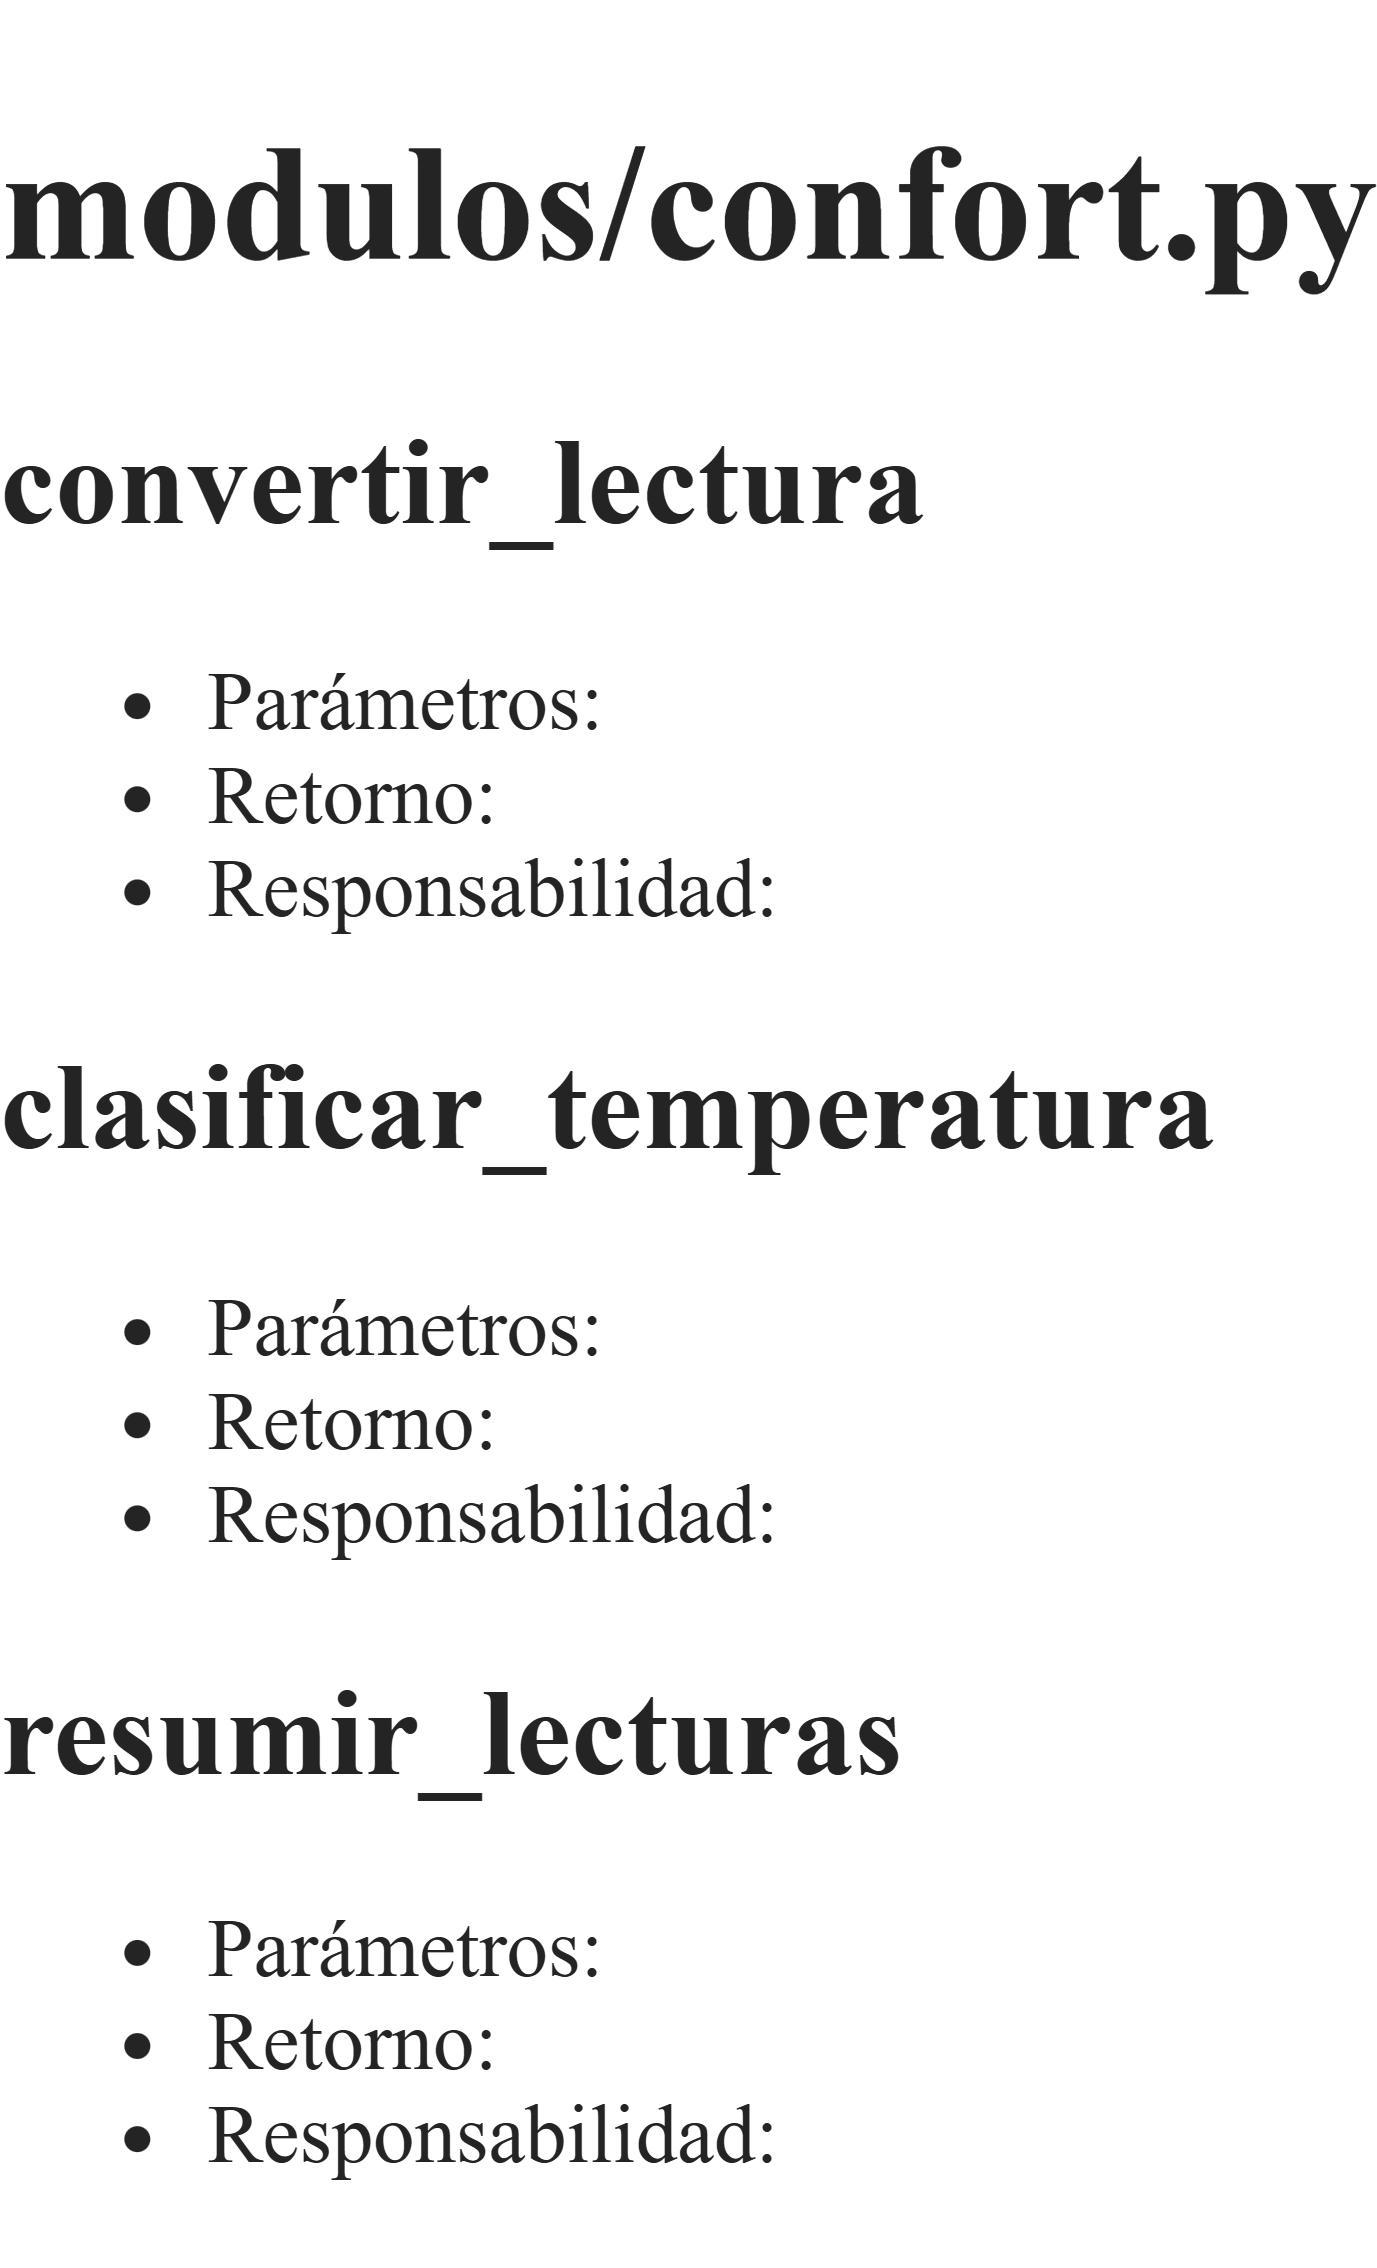
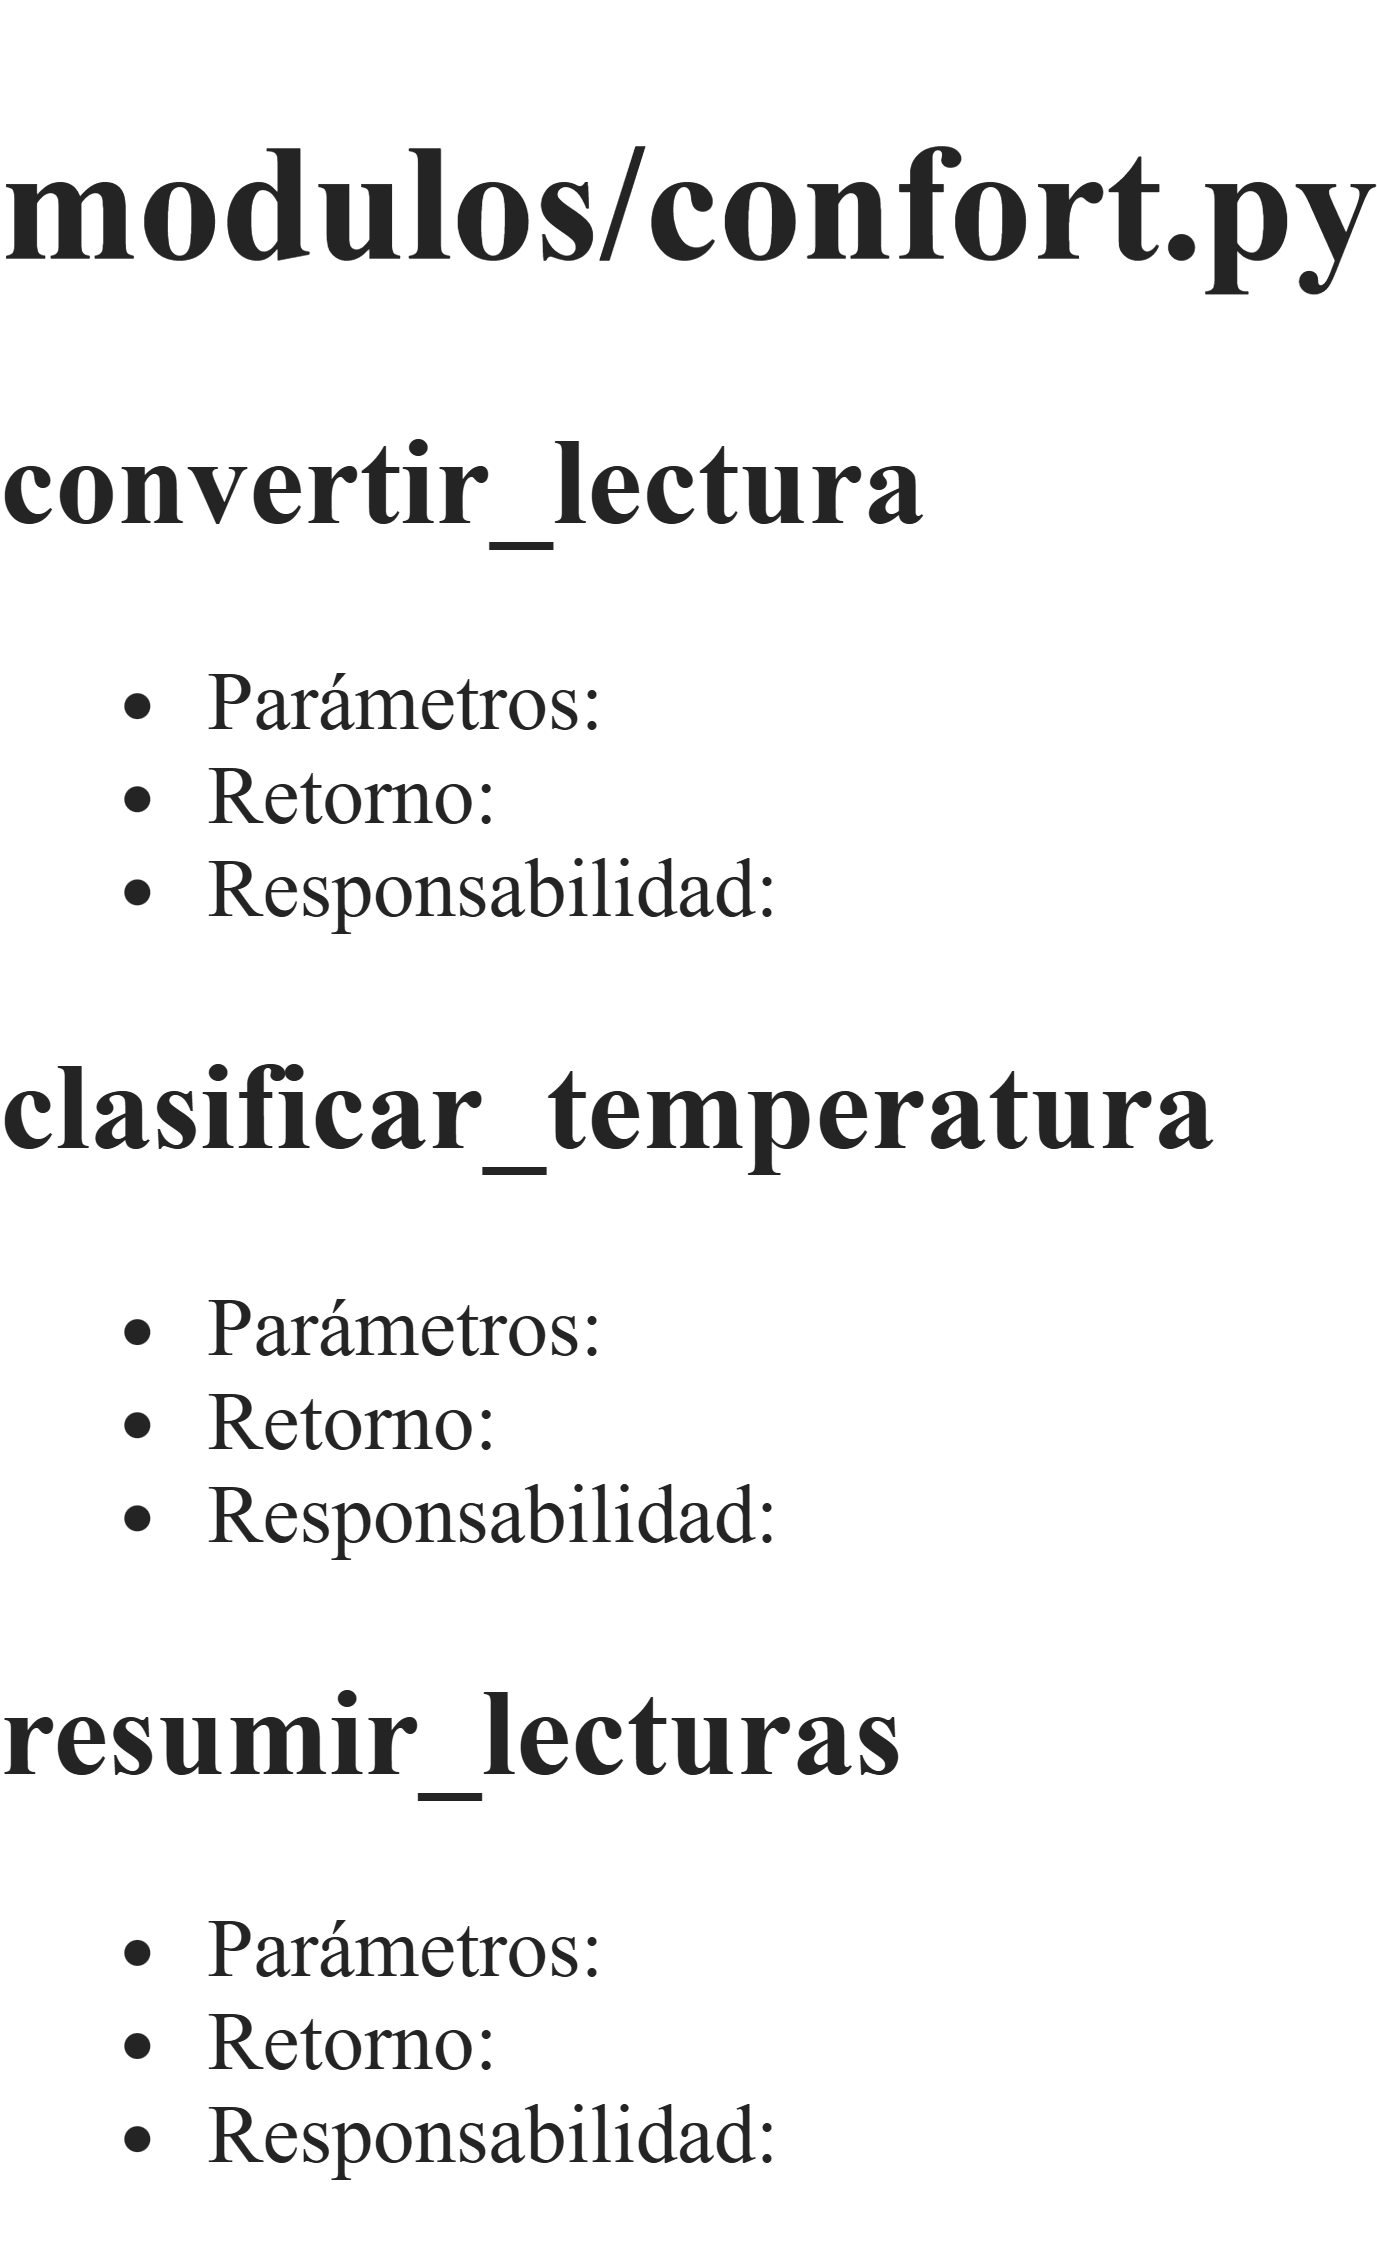

In [5]:
#if __name__ == "__main__":
    # for lectura in resumir_lecturas(["17.5", "18", "22.3", "27", "28.1"]).items():
    #print(lectura)

Ejercicio 11.03 · Pruebas de límites. Escribe una función es_humedad_adecuada que devuelva verdadero entre 30 y 65 ambos incluidos. Crea pruebas assert para 29.9, 30, 65, 65.1 y un caso normal.

In [6]:
def es_humedad_adecuada(humedad: float) -> bool:
    return 30 <= humedad <= 65


assert es_humedad_adecuada(29.9) is False
assert es_humedad_adecuada(30) is True
assert es_humedad_adecuada(65) is True
assert es_humedad_adecuada(65.1) is False

## Proyecto 11 · Mini-paquete de confort

Crea la carpeta modulos y el archivo confort.py. Incluye las funciones clasificar_temperatura, es_humedad_adecuada y describir_confort. La última debe recibir temperatura, humedad y sensor_activo; devolver revisar sensor cuando proceda; y en otro caso combinar las otras reglas en un mensaje. Añade docstrings, anotaciones y una demostración protegida por la condición principal.

Crea pruebas/test_confort.py con al menos seis pruebas pytest: una para el sensor inactivo, los límites de temperatura 18 y 27, los límites de humedad 30 y 65, y un caso fuera de rango. Ejecuta la suite desde la raíz con python menos m pytest pruebas. Incluye en el cuaderno una captura de texto o transcripción del resultado y una explicación de cómo actuarías si falla una prueba.

No copies lógica distinta en las pruebas: importa el módulo y llama a sus funciones. La solución debe funcionar desde un kernel reiniciado y desde la terminal del entorno virtual.

In [18]:
from pathlib import Path

carpeta = Path("modulos")
if not carpeta.exists():
    carpeta.mkdir()

archivo = Path().cwd()/"modulos"/"confort.py"
archivo.touch()

pruebas = Path("pruebas")
if not pruebas.exists():
    pruebas.mkdir()

test = Path().cwd()/"pruebas"/"test_confort.py"
test.touch()




================================================= test session starts =================================================
platform win32 -- Python 3.11.6, pytest-9.1.1, pluggy-1.6.0
rootdir: C:\Users\pajim\OneDrive\Escritorio\Master\Programacion IA\Proyecto\unidades
plugins: anyio-4.15.1, platformdirs-4.12.1
collected 6 items

pruebas\test_confort.py ......                                                                                   [100%]

================================================== 6 passed in 0.03s ==================================================

Si fallara cualquier prueba habría que ver cual es el mensaje de error y comprobar cual es el fallo

## Autoevaluación

Comprueba que puedes distinguir módulo, paquete y script; explicar por qué evitar importaciones con asterisco; describir qué hace la condición principal; justificar un caso límite de prueba; y localizar las primeras comprobaciones ante un error de importación.

## Para ampliar

- [Módulos en Python](https://docs.python.org/3/tutorial/modules.html)
- [Paquetes](https://docs.python.org/3/tutorial/modules.html#packages)
- [Documentación de pytest](https://docs.pytest.org/en/stable/)